# 01 · Cadrage métier et exploration des données
**Projet S7MOI1 — ECAM-EPMI · Maintenance prédictive · AI4I 2020**

Ce notebook documente le problème, vérifie les données et explore uniquement le train après séparation. Les sorties sont calculées sur le **CSV officiel**, lui-même synthétique ; aucun jeu de remplacement n'est généré.

## 1. Décision et critères de succès
- **Contexte :** atelier d'usinage instrumenté ; utilisateur : responsable maintenance.
- **Problème :** les arrêts imprévus perturbent la production.
- **Décision :** prioriser une inspection à partir de mesures disponibles au cycle courant. La disponibilité réelle de ces mesures avant l'action doit être validée sur site.
- **Situation actuelle :** maintenance calendaire ; faute de coûts calendaires observés, la comparaison économique utilise explicitement une référence simplifiée « aucune alerte prédictive ».
- **Succès visé à l'issue d'un pilote de 3 mois :** rappel ≥ 80 %, précision ≥ 1/3 (au plus deux fausses alertes par vraie alerte), gain net annuel positif dans le scénario pessimiste.
- **Contraintes :** décision humaine, capacité d'inspection, dérive des capteurs et absence d'horodatages.

**Type : classification binaire supervisée.** `machine_failure` vaut 0 ou 1. La régression de durée n'est pas possible sans cible de durée ; le clustering ignorerait les étiquettes disponibles. Aucun horizon à 24 h n'est démontré : la cible concerne l'observation courante.

## 2. Source et reproductibilité
[UCI AI4I 2020, id 601](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset), DOI [10.24432/C5HS5C](https://doi.org/10.24432/C5HS5C), licence **CC BY 4.0**, consulté le 23 octobre 2026. Déposé en 2020 ; aucune période réelle d'observation industrielle n'est fournie. Le CSV est inclus pour permettre une exécution hors ligne.

## Guide de lecture
**Question :** quelles données sont exploitables avant une panne ?

**À la fin :** connaître le vrai taux de panne, justifier chaque colonne exclue, expliquer les trois variables physiques et le split train/test.

**À savoir à l'oral :** 3,39 % de pannes signifie qu'un modèle disant toujours « normal » atteint déjà 96,61 % d'accuracy. La qualité du projet se juge donc surtout sur le rappel et la précision des alertes.

**Exécution :** ce notebook peut être relancé seul depuis le dossier complet. Les fonctions partagées sont expliquées dans `src/project.py`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src/project.py').exists() else Path.cwd().parent
assert (ROOT / 'src/project.py').exists(), 'Ouvrir depuis la racine du projet ou notebooks/.'
sys.path.insert(0, str(ROOT / 'src'))
from project import *
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top':False, 'axes.spines.right':False, 'figure.dpi':110})
pd.set_option('display.max_columns', 25)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches='tight')
    plt.show()


In [2]:
df = load_data()
train_idx, test_idx = split_indices(df)
assert not set(train_idx) & set(test_idx)
train = df.iloc[train_idx].copy()
pd.DataFrame({'index': np.r_[train_idx,test_idx], 'partition':['train']*len(train_idx)+['test']*len(test_idx)}).to_csv(RESULTS/'split.csv',index=False)
# Seuls l'inventaire et les contrôles de qualité ci-dessous portent sur l'ensemble.
display(pd.DataFrame({'lignes':[len(df)],'colonnes':[df.shape[1]],'pannes':[int(df.machine_failure.sum())], 'taux_panne':[df.machine_failure.mean()], 'manquants':[int(df.isna().sum().sum())], 'doublons_lignes':[int(df.duplicated().sum())], 'doublons_capteurs':[int(df.duplicated(FEATURES).sum())]}))
print(f'Train : {len(train_idx)} ; test réservé : {len(test_idx)}. Baseline globale sans panne : {1-df.machine_failure.mean():.2%} accuracy.')

Train : 8000 ; test réservé : 2000. Baseline globale sans panne : 96.61% accuracy.


,lignes,colonnes,pannes,taux_panne,manquants,doublons_lignes,doublons_capteurs
0,10000,14,339,0.0339,0,0,0


## 3. Dictionnaire et audit de fuite
Les modes de panne décrivent l'issue et sont exclus. Les identifiants ne sont pas des mesures physiques ; ils sont également exclus. La puissance est calculée **en watts** avec la vitesse convertie de tr/min en rad/s.

In [3]:
dictionary = pd.DataFrame([
['udi','entier','sans unité','identifiant de ligne','exclu'],['product_id','texte','sans unité','identifiant produit','exclu'],['type','catégorie','L/M/H','qualité produit','entrée'],['air_temp','réel','K','température air','entrée'],['process_temp','réel','K','température procédé','entrée'],['rot_speed','entier','tr/min','vitesse de rotation','entrée'],['torque','réel','N·m','couple mécanique','entrée'],['tool_wear','entier','min','usure accumulée outil','entrée'],['machine_failure','binaire','0/1','panne de cette observation','cible'], *[[m,'binaire','0/1','mode de panne constaté','fuite : exclu'] for m in MODES]], columns=['variable','type','unité','sens','usage'])
display(dictionary)
dictionary.to_csv(RESULTS/'dictionnaire.csv',index=False)
assert not set(FEATURES) & set(MODES+['udi','product_id','machine_failure'])
# Le label officiel fait foi : on ne le reconstruit pas à partir des modes.
inconsistent = df.machine_failure.ne(df[MODES].max(axis=1))
print('Lignes dont la cible diffère du OU des modes :', int(inconsistent.sum()))
print('Ces lignes sont conservées ; les modes ne servent ni au nettoyage de la cible ni au modèle.')
display(train[RAW_NUM].describe().round(2))
assert (train[['air_temp','process_temp','rot_speed','torque']] > 0).all().all()
assert (train.tool_wear >= 0).all()
assert set(train.type.unique()) <= {'L','M','H'}

Lignes dont la cible diffère du OU des modes : 27
Ces lignes sont conservées ; les modes ne servent ni au nettoyage de la cible ni au modèle.


,variable,type,unité,sens,usage
0,udi,entier,sans unité,identifiant de ligne,exclu
1,product_id,texte,sans unité,identifiant produit,exclu
2,type,catégorie,L/M/H,qualité produit,entrée
3,air_temp,réel,K,température air,entrée
4,process_temp,réel,K,température procédé,entrée
5,rot_speed,entier,tr/min,vitesse de rotation,entrée
6,torque,réel,N·m,couple mécanique,entrée
7,tool_wear,entier,min,usure accumulée outil,entrée
8,machine_failure,binaire,0/1,panne de cette observation,cible
9,TWF,binaire,0/1,mode de panne constaté,fuite : exclu


,air_temp,process_temp,rot_speed,torque,tool_wear
count,8000.00,8000.00,8000.00,8000.00,8000.00
mean,300.01,310.01,1539.36,40.00,107.68
std,2.00,1.48,180.98,10.02,63.61
min,295.30,305.70,1168.00,3.80,0.00
25%,298.30,308.80,1422.00,33.20,53.00
50%,300.10,310.10,1503.00,40.10,107.00
75%,301.50,311.10,1613.00,46.80,163.00
max,304.50,313.80,2886.00,76.60,253.00


**Traitement retenu :** aucune suppression automatique des valeurs extrêmes : un fonctionnement anormal peut être un signal de panne. Les imputations de secours et la standardisation seront apprises seulement dans les plis d'entraînement. Les éventuelles incohérences entre modes et cible sont signalées, sans réétiquetage arbitraire.

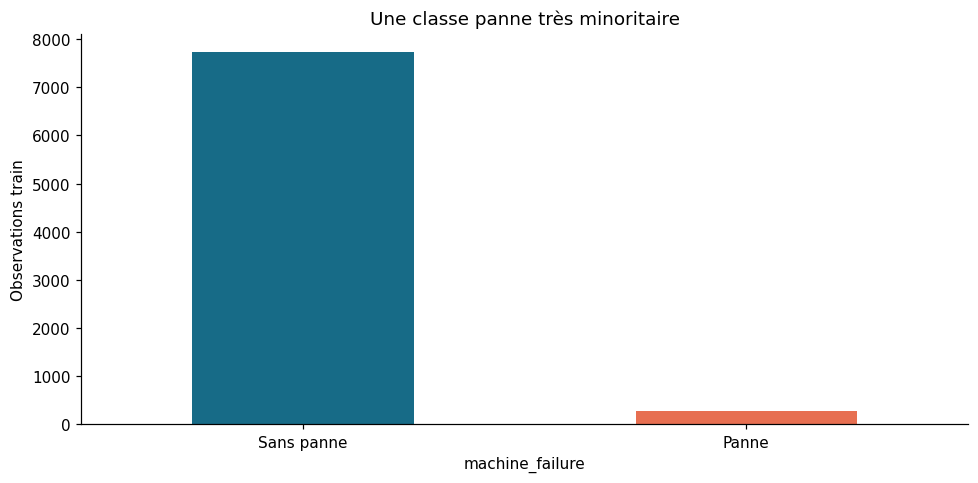

**Lecture :** 271 pannes sur 8000 observations train (3.39%). Une accuracy élevée seule ne suffit donc pas.

In [4]:
counts = train.machine_failure.value_counts().sort_index()
counts.plot.bar(color=['#176B87','#E76F51'],rot=0)
plt.xticks([0,1],['Sans panne','Panne']); plt.ylabel('Observations train'); plt.title('Une classe panne très minoritaire')
savefig('01_distribution.png')
display(Markdown(f'**Lecture :** {counts[1]} pannes sur {len(train)} observations train ({train.machine_failure.mean():.2%}). Une accuracy élevée seule ne suffit donc pas.'))

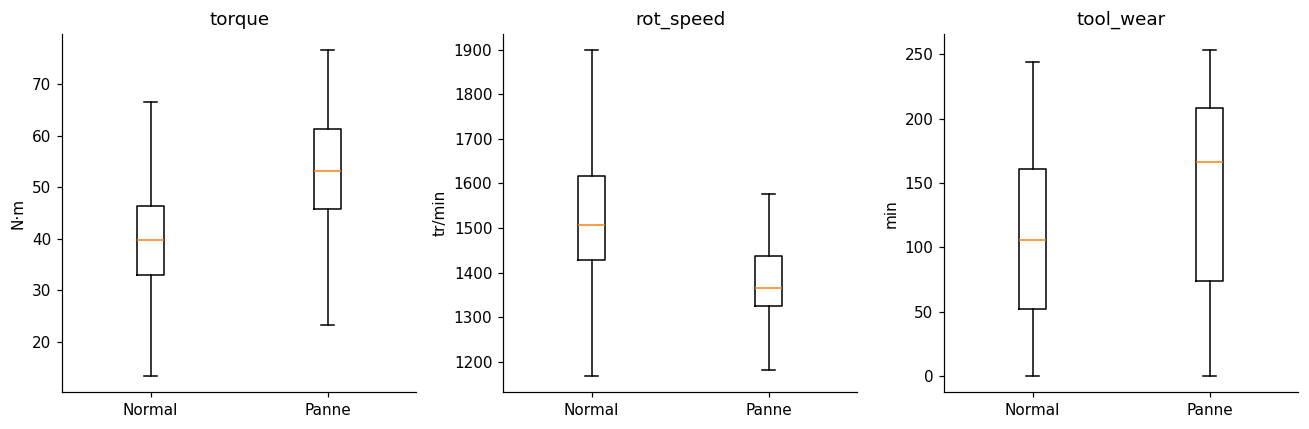

,torque,rot_speed,tool_wear
machine_failure,,,
0,39.8,1507.0,106.0
1,53.2,1366.0,166.0


In [5]:
fig, axes = plt.subplots(1,3,figsize=(12,4))
for ax,col,unit in zip(axes,['torque','rot_speed','tool_wear'],['N·m','tr/min','min']):
    ax.boxplot([train.loc[train.machine_failure==k,col] for k in [0,1]],tick_labels=['Normal','Panne'],showfliers=False)
    ax.set(title=col,ylabel=unit)
savefig('02_capteurs_cible.png')
display(train.groupby('machine_failure')[['torque','rot_speed','tool_wear']].median().round(2))

**Lecture :** les distributions des capteurs diffèrent selon la cible, avec un recouvrement : une seule valeur de couple ou d'usure ne suffit pas à décider. Les moustaches masquent visuellement les extrêmes pour la lisibilité ; les observations restent dans les données.

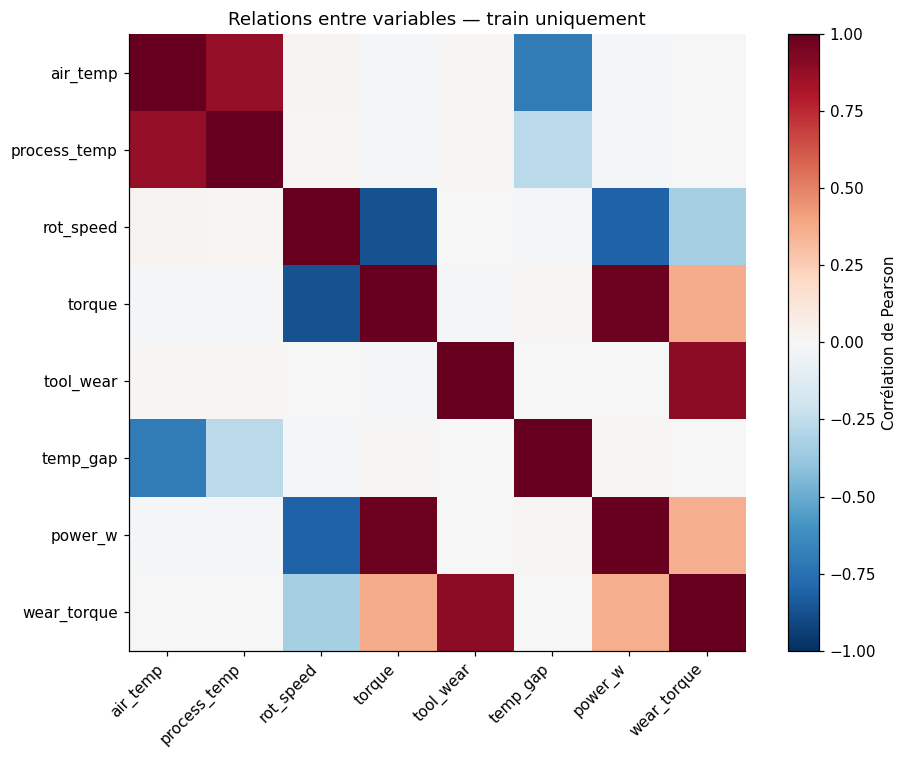

,temp_gap,power_w,wear_torque
count,8000.0,8000.00,8000.00
mean,10.0,6282.62,4302.68
std,1.0,1072.42,2820.18
min,7.6,1148.44,0.00
25%,9.3,5559.61,1953.32
50%,9.8,6272.29,3998.70
75%,11.0,7013.87,6265.05
max,12.1,10469.92,16497.00


In [6]:
enriched = PhysicalFeatures().fit_transform(train)
corr = enriched[RAW_NUM+ENGINEERED].corr()
fig,ax = plt.subplots(figsize=(9,7))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(corr)),corr.columns,rotation=45,ha='right'); ax.set_yticks(range(len(corr)),corr.columns)
fig.colorbar(im,ax=ax,label='Corrélation de Pearson'); ax.set_title('Relations entre variables — train uniquement')
savefig('03_correlations.png')
display(enriched[ENGINEERED].describe().round(2))

**Lecture :** certaines variables partagent de l'information physique ; leur corrélation ne prouve pas une causalité. Les trois variables construites sont : écart procédé-air (K), puissance mécanique (W), et usure × couple (min·N·m). Les règles de génération UCI rendent ces interactions particulièrement informatives : cela limite la généralisation à un atelier réel.

## 4. Conclusion et protocole figé
Le split stratifié 80/20 est fixé à `random_state=42`. Le notebook 02 utilise exclusivement les 8 000 lignes train. La sélection, le réglage et le seuil ne verront pas le test. Le notebook 03 ouvre le test après gel du choix. La séparation aléatoire répond à l'exercice, mais les marches aléatoires de température créent des dépendances : une validation chronologique et par machine sera nécessaire sur un historique réel.

In [7]:
# Synthèse vérifiable de l'exploration, calculée à partir du train.
medians = train.groupby('machine_failure')[['torque','rot_speed','tool_wear']].median()
display(Markdown(
    f"### Synthèse à retenir\n"
    f"- Taux global de panne : **{df.machine_failure.mean():.2%}**.\n"
    f"- Couple médian : **{medians.loc[0,'torque']:.1f} N·m** sans panne et **{medians.loc[1,'torque']:.1f} N·m** avec panne.\n"
    f"- Usure médiane : **{medians.loc[0,'tool_wear']:.0f} min** sans panne et **{medians.loc[1,'tool_wear']:.0f} min** avec panne.\n"
    "- Ces associations justifient la modélisation, mais ne démontrent pas de causalité."
))

### Synthèse à retenir
- Taux global de panne : **3.39%**.
- Couple médian : **39.8 N·m** sans panne et **53.2 N·m** avec panne.
- Usure médiane : **106 min** sans panne et **166 min** avec panne.
- Ces associations justifient la modélisation, mais ne démontrent pas de causalité.